# Extract M. genetalium Orthologs from PANTHER Database

This notebook queries the PANTHER database API to:
1. Download gene family mappings for all three organisms using `downloadgenome` endpoint
2. Identify orthologs by matching shared PANTHER family IDs across species.  
3. Compile results with PANTHER family IDs and gene details

**Approach:**
- Use `/downloadgenome` to get all gene-family mappings for each species
- Match orthologs by shared PANTHER family ID (genes in same family across species are orthologs)
- Extract UniProt IDs, gene names, and family IDs

**Key Species & Taxon IDs:**
- M. genitalium: 243273
- S. pombe: 284812
- S. cerevisiae: 559292

**Output:** Structured CSV files listing all genes for each species, all genes with no family assigned for each species, and a .json file keyed on families that exist in M. genitalium listing genes from all three species in that family saved to OUTPUT_DIR.

In [12]:

# ============================================================================
# Setup: Import libraries and configure parameters
# ============================================================================

import requests
import pandas as pd
import json
import time
from typing import Dict, List, Optional
import os

# PANTHER API base URL
# Note: no /v1 suffix; downloadgenome uses POST, not GET
PANTHER_API_URL = "https://pantherdb.org/services/oai/pantherdb"

# Species taxon IDs
SPECIES = {
    "M. genitalium": 243273,
    "S. pombe": 284812,
    "S. cerevisiae": 559292
}

# Output directory for todor PPI files
OUTPUT_DIR = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\todor"

print("✓ Libraries imported")
print(f"✓ PANTHER API: {PANTHER_API_URL}")
print(f"✓ Output directory: {OUTPUT_DIR}")


✓ Libraries imported
✓ PANTHER API: https://pantherdb.org/services/oai/pantherdb
✓ Output directory: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\todor


In [15]:

# ============================================================================
# Helper Functions: Query PANTHER API
# ============================================================================

def download_genome_families(taxon_id: int) -> pd.DataFrame:
    """
    Download all gene families for a given organism using the downloadgenome endpoint.
    
    The API returns a maximum of 1000 genes per request. This function paginates
    automatically using the startIndex parameter (1-based) until all genes are fetched.
    
    Uses POST to: https://pantherdb.org/services/oai/pantherdb/downloadgenome?organism=<taxon_id>
    
    Response JSON structure:
        data['search']['gene_list']['gene']  ->  list of gene records
        data['search']['number_of_genes_in_genome'] -> total genome size
        Each record has: gene_symbol, family_id, sf_id, accession, gene_name, family_name
        accession format: "SPECIES|Gene=SYMBOL|UniProtKB=XXXXX"

    Parameters
    ----------
    taxon_id : int
        NCBI taxon ID for the organism

    Returns
    -------
    pd.DataFrame
        DataFrame with columns: family_id, gene_id, gene_symbol, gene_name, uniprot_id, family_name
    """
    url = f"{PANTHER_API_URL}/downloadgenome"
    PAGE_SIZE = 1000

    all_records = []
    start_index = 1
    total_genes = None

    try:
        while True:
            params = {"organism": taxon_id, "startIndex": start_index}
            response = requests.post(url, params=params, timeout=120)
            response.raise_for_status()

            data   = response.json()
            search = data.get('search', {})

            # Capture total on first page
            if total_genes is None:
                total_genes = search.get('number_of_genes_in_genome', '?')
                print(f"  Total genes in genome: {total_genes}")

            genes = search.get('gene_list', {}).get('gene', [])
            if not genes:
                break  # No more data

            # Parse each gene record
            for gene in genes:
                accession  = gene.get('accession', '')
                uniprot_id = None
                for part in accession.split('|'):
                    if part.startswith('UniProtKB='):
                        uniprot_id = part.replace('UniProtKB=', '')
                        break

                all_records.append({
                    'family_id':   gene.get('family_id'),
                    'gene_id':     accession,
                    'gene_symbol': gene.get('gene_symbol'),
                    'gene_name':   gene.get('gene_name'),
                    'uniprot_id':  uniprot_id,
                    'family_name': gene.get('family_name'),
                })

            print(f"  Fetched genes {start_index}–{start_index + len(genes) - 1} "
                  f"({len(all_records)} of {total_genes} total)")

            # Stop if we have everything or the page was smaller than PAGE_SIZE
            if len(genes) < PAGE_SIZE or len(all_records) >= total_genes:
                break

            start_index += PAGE_SIZE
            time.sleep(0.5)  # Be polite to the API between pages

        families = pd.DataFrame(all_records)
        print(f"  ✓ Done: {len(families)} gene-family mappings retrieved")
        return families

    except requests.exceptions.RequestException as e:
        print(f"  ✗ API Error downloading genome: {e}")
        return pd.DataFrame()


def get_family_orthologs(family_id: str) -> Dict:
    """
    Get orthologs for a given PANTHER family across all organisms.

    Parameters
    ----------
    family_id : str
        PANTHER family ID (e.g., PTHR48418)

    Returns
    -------
    Dict
        Dictionary with ortholog results from PANTHER
    """
    url    = f"{PANTHER_API_URL}/familyortholog"
    params = {"family": family_id}

    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()
        data = response.json()

        if "results" in data:
            return data["results"]

        return {}

    except requests.exceptions.RequestException as e:
        print(f"  ✗ Ortholog API Error for {family_id}: {e}")
        return {}


def build_family_gene_lookup(df: pd.DataFrame) -> tuple:
    """
    Group gene records by family_id, preserving all genes per family.
    Genes with no PANTHER family ID (NaN) are excluded from the lookup
    and returned separately.

    Parameters
    ----------
    df : pd.DataFrame
        A species families DataFrame returned by download_genome_families(),
        with columns: family_id, gene_id, gene_symbol, gene_name, uniprot_id.

    Returns
    -------
    Tuple[Dict[str, List[Dict]], pd.DataFrame]
        - lookup: family_id -> list of gene dicts for that family
        - no_family_df: subset of df where family_id is NaN
    """
    # Separate genes with and without a PANTHER family assignment
    no_family_df = df[df['family_id'].isna()].copy()
    has_family_df = df[df['family_id'].notna()]

    lookup: Dict[str, List[Dict]] = {}
    for _, row in has_family_df.iterrows():
        fid = row['family_id']
        if fid not in lookup:
            lookup[fid] = []
        lookup[fid].append({
            'gene_id':     row['gene_id'],
            'gene_symbol': row['gene_symbol'],
            'gene_name':   row['gene_name'],

            'uniprot_id':  row['uniprot_id'],

        })

    return lookup, no_family_df

print("✓ Helper functions defined: download_genome_families(), get_family_orthologs(), build_family_gene_lookup()")

✓ Helper functions defined: download_genome_families(), get_family_orthologs(), build_family_gene_lookup()


In [ ]:

# ============================================================================
# Download Gene Family Mappings for All Three Species
# ============================================================================

print("Downloading gene family mappings from PANTHER...\n")

# Download genomes for all three species
mg_taxon_id = SPECIES["M. genitalium"]
sp_taxon_id = SPECIES["S. pombe"]
sc_taxon_id = SPECIES["S. cerevisiae"]

print(f"Downloading M. genitalium (taxon {mg_taxon_id})...")
mg_families = download_genome_families(mg_taxon_id)

print(f"\nDownloading S. pombe (taxon {sp_taxon_id})...")
sp_families = download_genome_families(sp_taxon_id)

print(f"\nDownloading S. cerevisiae (taxon {sc_taxon_id})...")
sc_families = download_genome_families(sc_taxon_id)

print("\n" + "="*70)
print(f"✓ M. genitalium:   {len(mg_families)} gene-family mappings")
print(f"✓ S. pombe:        {len(sp_families)} gene-family mappings")
print(f"✓ S. cerevisiae:   {len(sc_families)} gene-family mappings")
print("="*70)

# Show sample data structure
print("\nSample M. genitalium gene-family mapping:")
print(mg_families.head(2))

# ============================================================================
# Save raw family DataFrames to CSV
# ============================================================================

for df, filename in [
    (mg_families, "M_genitalium_families.csv"),
    (sp_families, "S_pombe_families.csv"),
    (sc_families, "S_cerevisiae_families.csv"),
]:
    path = os.path.join(OUTPUT_DIR, filename)
    df.to_csv(path, index=False)
    print(f"✓ Saved {filename} ({len(df)} rows) to:\n  {path}")



  Total genes in genome: 483
  Fetched genes 1–483 (483 of 483 total)
  ✓ Done: 483 gene-family mappings retrieved

  Total genes in genome: 5122
  Fetched genes 1–1000 (1000 of 5122 total)
  Fetched genes 1001–2000 (2000 of 5122 total)
  Fetched genes 2001–3000 (3000 of 5122 total)
  Fetched genes 3001–4000 (4000 of 5122 total)
  Fetched genes 4001–5000 (5000 of 5122 total)
  Fetched genes 5001–5122 (5122 of 5122 total)
  ✓ Done: 5122 gene-family mappings retrieved

  Total genes in genome: 6060
  Fetched genes 1–1000 (1000 of 6060 total)
  Fetched genes 1001–2000 (2000 of 6060 total)
  Fetched genes 2001–3000 (3000 of 6060 total)
  Fetched genes 3001–4000 (4000 of 6060 total)
  Fetched genes 4001–5000 (5000 of 6060 total)
  Fetched genes 5001–6000 (6000 of 6060 total)
  Fetched genes 6001–6060 (6060 of 6060 total)
  ✓ Done: 6060 gene-family mappings retrieved

✓ M. genitalium:   483 gene-family mappings
✓ S. pombe:        5122 gene-family mappings
✓ S. cerevisiae:   6060 gene-family

In [17]:

# ============================================================================
# Build Ortholog Relationships from Family Data
# ============================================================================
# Structure: family_orthologs[family_id] = {
#     "Mg_genes": [ {gene_id, gene_symbol, gene_name, uniprot_id}, ... ],
#     "Sp_genes": [ {gene_id, gene_symbol, gene_name, uniprot_id}, ... ],
#     "Sc_genes": [ {gene_id, gene_symbol, gene_name, uniprot_id}, ... ],
# }
# Multiple genes per species can share the same family (paralogs/co-orthologs).

# Load cached family DataFrames from CSV (avoids re-running the API calls)

mg_families = pd.read_csv(os.path.join(OUTPUT_DIR, "M_genitalium_families.csv"))
sp_families = pd.read_csv(os.path.join(OUTPUT_DIR, "S_pombe_families.csv"))
sc_families = pd.read_csv(os.path.join(OUTPUT_DIR, "S_cerevisiae_families.csv"))
print(f"✓ Loaded from CSV: M. genitalium ({len(mg_families)}), "
      f"S. pombe ({len(sp_families)}), S. cerevisiae ({len(sc_families)}) gene-family mappings")

# Build per-species family → gene-list lookups
# build_family_gene_lookup returns (lookup dict, no-family DataFrame)
mg_family_lookup, mg_no_family = build_family_gene_lookup(mg_families)
sp_family_lookup, sp_no_family = build_family_gene_lookup(sp_families)
sc_family_lookup, sc_no_family = build_family_gene_lookup(sc_families)

# Save genes with no PANTHER family assignment to CSV
for no_family_df, filename in [
    (mg_no_family, "M_genitalium_genes_no_family.csv"),
    (sp_no_family, "S_pombe_genes_no_family.csv"),
    (sc_no_family, "S_cerevisiae_genes_no_family.csv"),
]:
    path = os.path.join(OUTPUT_DIR, filename)
    no_family_df.to_csv(path, index=False)
    print(f"✓ Saved {len(no_family_df)} genes with no family ID to: {filename}")

# Build the ortholog dict anchored on M. genitalium families
family_orthologs: Dict[str, Dict] = {}

for fid, mg_genes in mg_family_lookup.items():
    family_orthologs[fid] = {
        "Mg_genes": mg_genes,
        "Sp_genes": sp_family_lookup.get(fid, []),
        "Sc_genes": sc_family_lookup.get(fid, []),
    }

# Summary
n_families      = len(family_orthologs)
n_mg_genes      = sum(len(v["Mg_genes"]) for v in family_orthologs.values())
n_sp_orthologs  = sum(1 for v in family_orthologs.values() if v["Sp_genes"])
n_sc_orthologs  = sum(1 for v in family_orthologs.values() if v["Sc_genes"])
n_both          = sum(1 for v in family_orthologs.values() if v["Sp_genes"] and v["Sc_genes"])
n_none          = sum(1 for v in family_orthologs.values() if not v["Sp_genes"] and not v["Sc_genes"])

print(f"\n✓ Built family_orthologs dict with {n_families} M. genitalium families "
      f"covering {n_mg_genes} genes\n")
print("=" * 60)
print(f"Families with S. pombe orthologs:        {n_sp_orthologs}")
print(f"Families with S. cerevisiae orthologs:   {n_sc_orthologs}")
print(f"Families with orthologs in BOTH:         {n_both}")
print(f"Families with no orthologs in either:    {n_none}")
print("=" * 60)

# Show a sample family that has genes in all three species
sample_fid = next(
    (fid for fid, v in family_orthologs.items() if v["Sp_genes"] and v["Sc_genes"]),
    next(iter(family_orthologs))
)
sample = family_orthologs[sample_fid]
print(f"\nSample family: {sample_fid}")
print(f"  Mg_genes ({len(sample['Mg_genes'])}): {[g['gene_symbol'] for g in sample['Mg_genes']]}")
print(f"  Sp_genes ({len(sample['Sp_genes'])}): {[g['gene_symbol'] for g in sample['Sp_genes']]}")
print(f"  Sc_genes ({len(sample['Sc_genes'])}): {[g['gene_symbol'] for g in sample['Sc_genes']]}")


# ============================================================================

# Save family_orthologs dict to JSON in OUTPUT_DIR

# ============================================================================

output_json = os.path.join(OUTPUT_DIR, "M_genitalium_orthologs_by_family.json")

with open(output_json, "w") as f:
    json.dump(family_orthologs, f, indent=2)

print(f"\n✓ Saved family_orthologs ({len(family_orthologs)} families) to:\n  {output_json}")

✓ Loaded from CSV: M. genitalium (483), S. pombe (5122), S. cerevisiae (6060) gene-family mappings
✓ Saved 134 genes with no family ID to: M_genitalium_genes_no_family.csv
✓ Saved 768 genes with no family ID to: S_pombe_genes_no_family.csv
✓ Saved 1289 genes with no family ID to: S_cerevisiae_genes_no_family.csv

✓ Built family_orthologs dict with 322 M. genitalium families covering 349 genes

Families with S. pombe orthologs:        167
Families with S. cerevisiae orthologs:   161
Families with orthologs in BOTH:         160
Families with no orthologs in either:    154

Sample family: PTHR10344
  Mg_genes (1): ['tmk']
  Sp_genes (1): ['tmp1']
  Sc_genes (1): ['CDC8']

✓ Saved family_orthologs (322 families) to:
  G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\todor\M_genitalium_orthologs_by_family.json


In [18]:

# ============================================================================
# Find PANTHER families that contain S. pombe Priority Unstudied Genes (PUGs)
# ============================================================================

PLDDT_TSV = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes\intermediate_files\plddt_all_genes_vs_PUGs.tsv"

# Load gene annotation file and filter to Priority Unstudied genes only
plddt_df = pd.read_csv(PLDDT_TSV, sep="\t")
pug_df = plddt_df[plddt_df["is_priority_unstudied"] == True][
    ["gene_systematic_id", "gene_name", "uniprot_id"]
].copy()
print(f"✓ Loaded {len(plddt_df)} S. pombe genes; {len(pug_df)} are Priority Unstudied (PUGs)")

# Build a set of PUG UniProt IDs for fast lookup
pug_uniprot_ids = set(pug_df["uniprot_id"].dropna())

# Search family_orthologs for families containing at least one PUG
# Each Sp_genes entry has a 'uniprot_id' field from the PANTHER download
rows = []
for family_id, v in family_orthologs.items():
    for sp_gene in v["Sp_genes"]:
        if sp_gene["uniprot_id"] in pug_uniprot_ids:
            # Look up full annotation from plddt_df for this gene
            match = pug_df[pug_df["uniprot_id"] == sp_gene["uniprot_id"]]
            if not match.empty:
                row = match.iloc[0]
                rows.append({
                    "Family_ID":          family_id,
                    "Sp_gene_systematic_id": row["gene_systematic_id"],
                    "Sp_gene_name":          row["gene_name"],
                    "Sp_uniprot_id":         row["uniprot_id"],
                    "Mg_gene_symbols":       ", ".join(
                        g["gene_symbol"] for g in v["Mg_genes"] if g["gene_symbol"]
                    ),
                    "Mg_gene_ids":           ", ".join(
                        g["gene_id"] for g in v["Mg_genes"]
                    ),
                })

df_pug_families = pd.DataFrame(rows)

print(f"\n✓ Found {len(df_pug_families)} PUG–M. genitalium family associations "
      f"across {df_pug_families['Family_ID'].nunique()} families "
      f"({df_pug_families['Sp_gene_systematic_id'].nunique()} unique PUGs)")

print("\nSample results:")
print(df_pug_families.head(5).to_string(index=False))

# Save to OUTPUT_DIR
output_path = os.path.join(OUTPUT_DIR, "Sp_PUGs_in_Mg_families.csv")
df_pug_families.to_csv(output_path, index=False)
print(f"\n✓ Saved to:\n  {output_path}")


✓ Loaded 5124 S. pombe genes; 122 are Priority Unstudied (PUGs)

✓ Found 1 PUG–M. genitalium family associations across 1 families (1 unique PUGs)

Sample results:
Family_ID Sp_gene_systematic_id Sp_gene_name Sp_uniprot_id Mg_gene_symbols                                 Mg_gene_ids
PTHR10286           SPAC3A12.02         ceo2        P87118             ppa MYCGE|EnsemblGenome=MG_351|UniProtKB=P47593

✓ Saved to:
  G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\todor\Sp_PUGs_in_Mg_families.csv


In [22]:

# ============================================================================
# Load Todor et al. 2026 predicted PPI scores
# ============================================================================
# The dataset is a pair of symmetric matrices (476 × 476) — one per scoring
# method — where both rows and columns are M. genitalium gene identifiers
# (MG_001 … MG_476).  We load both sheets once here and index them on the
# gene-name column so individual rows can be retrieved in O(1).

TODOR_XLSX = os.path.join(
    OUTPUT_DIR,
    "44320_2026_189_MOESM7_ESM.xlsx"
)

# Read both score matrices; the first column ("Unnamed: 0") contains the row
# gene names — set it as the DataFrame index.
_sc_iptm = pd.read_excel(
    TODOR_XLSX, sheet_name="size_corrected ipTM", index_col=0
)
_raw_iptm = pd.read_excel(
    TODOR_XLSX, sheet_name="raw ipTM", index_col=0
)

print(f"✓ Loaded Todor et al. 2026 PPI matrices: "
      f"{_sc_iptm.shape[0]} × {_sc_iptm.shape[1]} genes")

# Build gene-level annotation lookups keyed on the matrix label (MG_001 etc.)
# The mg_families gene_id field contains "MYCGE|EnsemblGenome=MG_001|UniProtKB=..."
# which gives us the matrix-compatible key.
_mg_annot = mg_families.copy()
_mg_annot["matrix_id"] = _mg_annot["gene_id"].str.extract(r"EnsemblGenome=(MG_\d+)")
_mg_annot = _mg_annot.dropna(subset=["matrix_id"]).set_index("matrix_id")

# Deduplicate: keep first occurrence per matrix_id (handles rare multi-family cases)
_mg_annot = _mg_annot[~_mg_annot.index.duplicated(keep="first")]

_mg_uniprot = _mg_annot["uniprot_id"].to_dict()   # MG_001 → UniProt ID
_mg_family  = _mg_annot["family_id"].to_dict()    # MG_001 → PANTHER family ID

# Build family → ortholog UniProt ID lookups from family_orthologs
# family_id → list of S. pombe UniProt IDs in that family
_sp_orthologs_by_family: Dict[str, List[str]] = {
    fid: [g["uniprot_id"] for g in v["Sp_genes"] if g["uniprot_id"]]
    for fid, v in family_orthologs.items()
}
# family_id → list of S. cerevisiae UniProt IDs in that family
_sc_orthologs_by_family: Dict[str, List[str]] = {
    fid: [g["uniprot_id"] for g in v["Sc_genes"] if g["uniprot_id"]]
    for fid, v in family_orthologs.items()
}

print(f"✓ Built annotation lookups for {len(_mg_uniprot)} M. genitalium genes")


def get_ppi_scores(gene: str) -> pd.DataFrame:
    """
    Extract predicted interaction scores for one M. genitalium gene.

    Retrieves the row for `gene` from the size_corrected_iPTM and raw_iPTM
    matrices (Todor et al. 2026), merges them into a single DataFrame indexed
    by partner gene name, removes the self-interaction (NaN diagonal), adds
    UniProt ID and PANTHER family ID for each partner gene, and sorts by
    size_corrected_iPTM descending.

    Parameters
    ----------
    gene : str
        M. genitalium gene identifier, e.g. "MG_351".

    Returns
    -------
    pd.DataFrame
        Columns: size_corrected_iPTM, raw_iPTM, uniprot_id, family_id,
                 Sp_ortholog_uniprots, Sc_ortholog_uniprots
        Index: partner gene name (all other MG genes)
        Sorted by size_corrected_iPTM descending.

    Raises
    ------
    KeyError
        If `gene` is not found in the score matrices.
    """
    if gene not in _sc_iptm.index:
        raise KeyError(
            f"Gene '{gene}' not found in the PPI matrices. "
            f"Available genes: {list(_sc_iptm.index[:5])} ..."
        )

    sc_row  = _sc_iptm.loc[gene].rename("size_corrected_iPTM")
    raw_row = _raw_iptm.loc[gene].rename("raw_iPTM")

    df = pd.concat([sc_row, raw_row], axis=1)

    # Drop the self-interaction (NaN on the diagonal)
    df = df.dropna(subset=["size_corrected_iPTM"])

    # Add UniProt ID and PANTHER family ID for each partner gene
    df["uniprot_id"] = df.index.map(_mg_uniprot)
    df["family_id"]  = df.index.map(_mg_family)

    # Add S. pombe and S. cerevisiae ortholog UniProt IDs (as lists) via family membership
    df["Sp_ortholog_uniprots"] = df["family_id"].map(
        lambda fid: _sp_orthologs_by_family.get(fid, []) if pd.notna(fid) else []
    )
    df["Sc_ortholog_uniprots"] = df["family_id"].map(
        lambda fid: _sc_orthologs_by_family.get(fid, []) if pd.notna(fid) else []
    )

    # Sort strongest predicted interactions first
    df = df.sort_values("size_corrected_iPTM", ascending=False)
    df.index.name = "partner_gene"

    return df


print("✓ Function defined: get_ppi_scores(gene)")
print("\nExample — top 10 predicted interactions for MG_351:")
example = get_ppi_scores("MG_351")
print(example.head(10).to_string())


✓ Loaded Todor et al. 2026 PPI matrices: 476 × 476 genes
✓ Built annotation lookups for 476 M. genitalium genes
✓ Function defined: get_ppi_scores(gene)

Example — top 10 predicted interactions for MG_351:
              size_corrected_iPTM  raw_iPTM uniprot_id  family_id      Sp_ortholog_uniprots                      Sc_ortholog_uniprots
partner_gene                                                                                                                         
MG_096                   0.042151     0.135     P47342  PTHR46136                        []                                        []
MG_034                   0.019181     0.072     P47280  PTHR11441                        []                                        []
MG_461                   0.013933     0.088     P47699  PTHR11373                        []                                        []
MG_460                   0.012693     0.076     P47698  PTHR43128                  [Q9P7P7]                                 

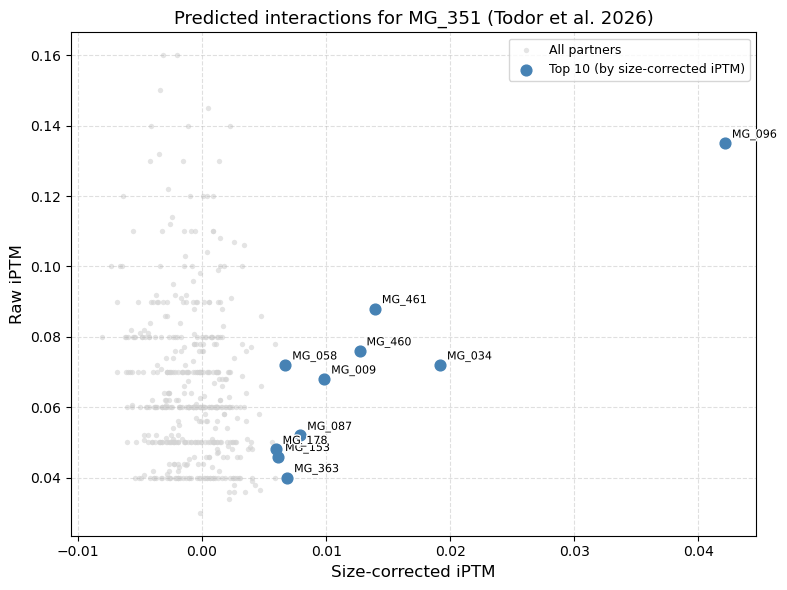

In [20]:

# ============================================================================
# Scatter plot: size_corrected_iPTM vs raw_iPTM for MG_351
# ============================================================================

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

QUERY_GENE = "MG_351"
TOP_N = 10

df_plot = get_ppi_scores(QUERY_GENE).reset_index()

top10 = df_plot.head(TOP_N)
rest  = df_plot.iloc[TOP_N:]

fig, ax = plt.subplots(figsize=(8, 6))

# All other genes — small grey dots
ax.scatter(
    rest["size_corrected_iPTM"],
    rest["raw_iPTM"],
    s=15, color="lightgrey", alpha=0.6, linewidths=0, zorder=1,
    label="All partners"
)

# Top 10 — coloured, larger dots
scatter = ax.scatter(
    top10["size_corrected_iPTM"],
    top10["raw_iPTM"],
    s=60, color="steelblue", zorder=3,
    label=f"Top {TOP_N} (by size-corrected iPTM)"
)

# Label the top 10 points
for _, r in top10.iterrows():
    ax.annotate(
        r["partner_gene"],
        xy=(r["size_corrected_iPTM"], r["raw_iPTM"]),
        xytext=(5, 4), textcoords="offset points",
        fontsize=8, zorder=4,
        path_effects=[pe.withStroke(linewidth=2, foreground="white")]
    )

ax.set_xlabel("Size-corrected iPTM", fontsize=12)
ax.set_ylabel("Raw iPTM", fontsize=12)
ax.set_title(f"Predicted interactions for {QUERY_GENE} (Todor et al. 2026)", fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()
